# Decay fit vs snow

This notebook predicts 12-day coherence from the per-pixel temporal decay fit and subtracts it from the observed 12-day NISAR coherence. The difference ($\gamma_{obs} - \gamma_{pred}$) is then compared with terrain, vegetation and snow metrics.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import rioxarray  # noqa: F401
import xrspatial as xrs
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.taus import decorrelation_temporal_model
from scripts.stations import read_mesowest, read_snotel, pair_metrics
from scripts.fsca import classify_fsca, classify_change

First, we setup logging to get useful information and error messages.

In [2]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True
)

All the settings you are likely to change are in this one cell. The decay fit and the coherence cube must come from the same track and resolution.

In [3]:
data_dir = "../data/"
track = 19
frame = 21
res = '80m'

# decay fit (tau, gamma_inf, gamma_0, nse, success) and the NISAR coherence cube (pair, y, x)
decay_path = data_dir + f'nisar/zarrs/all_pairs/track{track:03d}/decay_summer_nosetgamma_{res}.zarr'
coh_path = data_dir + f'nisar/zarrs/all_pairs/track{track:03d}/coherence_{res}.zarr'
# cube with the static layers (elevation, canopy_2019) for this frame
static_path = data_dir + f'nisar/zarrs/track{track:03d}_frame{frame:03d}/coherence_{res}.zarr'
fsca_path = data_dir + f'fsca_spires/zarrs/erb_fsca_{res}.zarr'
aso_path = data_dir + 'aso/er_20260318/ASO_EastRiver_2026Mar18_snowdepth_3m.tif'
aso_date = '2026-03-18'

coh_var = None          # None = use the variable the decay fit was made from (decay attrs 'var')
start_date = '2025-12-29'
end_date = '2026-05-01'
target_days = 12        # temporal baseline to predict and compare
day_tol = 0.5           # pairs within target_days +/- day_tol are kept
min_nse = 0.0           # mask pixels where the decay fit has NSE below this
canopy_max = 100        # only use pixels with canopy cover (%) <= this
elev_min = 0            # only use pixels with elevation (m) >= this

selected_pair = '20260215_20260227'    # e.g. '20260203_20260215'; None = first wet pair (or the last pair)
wet_after = '2026-02-28'  # pairs starting after this date are drawn as wet
no_snow_after = '2026-03-'

swe_stns = ['schofield_pass']
wind_stns = ['CACNM', 'CASCP']
event_threshold = 6     # mm of SWE, defines a snow event
event_freq = '12h'
focus_metric = 'swe_max_12h'  # metric for the single annotated scatter

elev_step = 100                          # m
canopy_bins = [0, 20, 30, 40, 50, 60, 70, 100]  # %
slope_min = 5                            # deg; flatter pixels have no aspect

save_outputs = False
out_name = f'decay_vs_snow_track{track:03d}_{res}'
out_dir = '../outputs/'

Helper functions used below: matching grids, binning statistics and the aspect rose.

In [4]:
sector_names = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']


def match_grid(da, ref, crs):
    """Return `da` on the x/y grid of `ref`. Nothing is resampled if the grids already agree."""
    same = (da.sizes['x'] == ref.sizes['x'] and da.sizes['y'] == ref.sizes['y']
            and np.allclose(da['x'], ref['x']) and np.allclose(da['y'], ref['y']))
    if same:
        return da.assign_coords(x=ref['x'].values, y=ref['y'].values)
    logging.info('Resampling %s onto the reference grid', da.name)
    if da.rio.crs is None:
        da = da.rio.write_crs(crs)
    return da.rio.reproject_match(ref.rio.write_crs(crs), resampling=Resampling.nearest)


def band_stats(values, y, bins):
    """Mean, std and count of `y` in each bin of `values`."""
    cut = pd.cut(values, bins=bins, include_lowest=True)
    g = y.groupby(cut, observed=True).agg(['mean', 'std', 'count'])
    g['mid'] = [iv.mid for iv in g.index]
    return g


def aspect_stats(aspect, y, width=45):
    """Band statistics in aspect sectors of `width` degrees, centered so north is the middle of a sector."""
    shifted = (aspect + width / 2) % 360 - width / 2
    s = band_stats(shifted, y, np.arange(-width / 2, 360, width))
    s['mid'] = s['mid'] % 360
    return s.sort_values('mid')


def plot_rose(ax, stats, ylabel, label=None):
    """Polar bar plot of mean values in 45 degree aspect sectors (N at the top, clockwise)."""
    ax.bar(np.deg2rad(stats['mid']), stats['mean'], width=np.deg2rad(45), alpha=0.8, label=label)
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
    ax.set_xticklabels(sector_names)
    ax.set_rlim(0, 1)
    ax.set_title(ylabel)


def pair_label(p):
    """'20260203_20260215' -> '02/03-02/15'"""
    return f'{p[4:6]}/{p[6:8]}-{p[13:15]}/{p[15:17]}'


def map_panels(da, ncols=4, **kwargs):
    """One map per pair with the date range as title."""
    g = da.plot(col='pair', col_wrap=min(ncols, da.sizes['pair']), **kwargs)
    for ax, p in zip(g.axs.flat, da['pair'].values):
        ax.set_title(pair_label(str(p)))
        ax.set_aspect('equal')
        ax.grid(False)
        ax.set_xlabel('')
        ax.set_ylabel('')
    return g

# 1. Predict 12-day coherence and difference the observations

Open the decay fit and the coherence cube. The fit is a single map per parameter, the cube has one layer per date pair.

In [5]:
fit = xr.open_zarr(decay_path, consolidated=False).load()
# fits made before the rename have r2 (= NSE) and no gamma_0 (it was fixed at 1)
if 'nse' not in fit:
    fit = fit.rename(r2='nse')
if 'gamma_0' not in fit:
    fit['gamma_0'] = xr.ones_like(fit['tau'])
coh = xr.open_zarr(coh_path)

if coh_var is None:
    coh_var = fit.attrs['var']
crs = coh.rio.crs if coh.rio.crs is not None else coh.attrs.get('crs', 'EPSG:32613')
print('decay fit window:', fit.attrs.get('start_date'), 'to', fit.attrs.get('end_date'), '| variable:', coh_var)
fit

decay fit window: 2026-05-10 to None | variable: gamma_temporal


/tmp/ipykernel_251759/3133413324.py:2: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  coh = xr.open_zarr(coh_path)


<xarray.Dataset> Size: 4MB
Dimensions:    (y: 566, x: 433)
Coordinates:
  * y          (y) float64 5kB 4.324e+06 4.324e+06 ... 4.279e+06 4.279e+06
  * x          (x) float64 3kB 3.151e+05 3.152e+05 ... 3.496e+05 3.496e+05
Data variables:
    tau        (y, x) float32 980kB nan nan nan nan nan ... nan nan nan nan nan
    n_pairs    (y, x) int16 490kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    gamma_inf  (y, x) float32 980kB nan nan nan nan nan ... nan nan nan nan nan
    success    (y, x) bool 245kB False False False False ... False False False
    r2         (y, x) float32 980kB nan nan nan nan nan ... nan nan nan nan nan
Attributes: (12/13)
    crs:          EPSG:32613
    var:          gamma_temporal
    n_pairs_fit:  55
    tile_size:    256
    stores:       ['/bsuhome/julialober/scratch/coherence_data/nisar/zarrs/al...
    start_date:   2026-05-10
    ...           ...
    max_days:     None
    gamma_inf:    fit
    tau_guess:    6
    tau_bounds:   [0, 30]
    min_pairs:    10
    metrics:      []

Keep only pairs whose temporal baseline is the target (12 days) and that fall inside the chosen time frame.

In [6]:
days = (coh['end'] - coh['start']) / np.timedelta64(1, 'D')
keep = ((abs(days - target_days) <= day_tol)
        & (coh['start'] >= np.datetime64(start_date))
        & (coh['end'] < np.datetime64(end_date) + np.timedelta64(1, 'D')))
keep = np.where(keep.values)[0]
if len(keep) == 0:
    raise ValueError(f'No {target_days}-day pairs between {start_date} and {end_date}')

coh_obs = coh[coh_var].isel(pair=keep).load()
coh_obs.name = 'coh_obs'
pairs = coh_obs['pair'].values.astype(str)
starts = coh_obs['start'].values
ends = coh_obs['end'].values
wet = starts > np.datetime64(wet_after)
grid_ref = coh_obs.isel(pair=0).drop_vars(['pair', 'start', 'end'])  # one layer, only used for its x/y grid
print(f'{len(pairs)} pairs:', *pairs)

10 pairs: 20251229_20260110 20260110_20260122 20260122_20260203 20260203_20260215 20260215_20260227 20260227_20260311 20260311_20260323 20260323_20260404 20260404_20260416 20260416_20260428


The static layers give elevation, canopy cover and aspect. They are put on the same grid as the coherence cube and used to mask pixels.

In [7]:
static = xr.open_zarr(static_path)
elevation = match_grid(static['elevation'].load(), grid_ref, crs)
canopy = match_grid(static['canopy_2019'].load(), grid_ref, crs)

slope = xrs.slope(elevation)
aspect = xrs.aspect(elevation).where(slope > slope_min)  # degrees clockwise from north, NaN where flat

valid = (canopy <= canopy_max) & (elevation >= elev_min)
print(f'{float(valid.mean()) * 100:.0f}% of pixels pass the canopy / elevation mask')

2026-11-04 15:02:03,784 - INFO - Resampling elevation onto the reference grid
2026-11-04 15:02:03,818 - INFO - Resampling canopy_2019 onto the reference grid


49% of pixels pass the canopy / elevation mask


The predicted coherence is $\gamma_\infty + (1-\gamma_\infty)e^{-t/\tau}$ evaluated at the target baseline. Pixels with a failed fit, or low $r^2$, are masked.

In [8]:
good = fit['success'].astype(bool) & (fit['nse'] >= min_nse)
fit_grid = {k: match_grid(fit[k], grid_ref, crs) for k in ['gamma_0', 'gamma_inf', 'tau', 'nse']}
good = match_grid(good.rename('good'), grid_ref, crs).astype(bool)

coh_pred = decorrelation_temporal_model(target_days, fit_grid['gamma_0'], fit_grid['gamma_inf'], fit_grid['tau']).where(good & valid)
coh_pred.name = 'coh_pred'
coh_pred.attrs = {'long_name': f'predicted {target_days}-day coherence'}

Subtract the predicted coherence from every observed pair. Negative values mean the pair is less coherent than the dry-snow decay predicts.

In [9]:
coh_diff = (coh_obs - coh_pred)
coh_diff.name = 'coh_diff'
coh_diff.attrs = {'long_name': 'observed minus predicted coherence'}
coh_diff

<xarray.DataArray 'coh_diff' (pair: 10, y: 566, x: 433)> Size: 10MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(10, 566, 433), dtype=float32)
Coordinates:
  * pair         (pair) <U17 680B '20251229_20260110' ... '20260416_20260428'
    start        (pair) datetime64[ns] 80B 2025-12-29T05:11:39.694737 ... 202...
    end          (pair) datetime64[ns] 80B 2026-01-10T05:11:40.389474 ... 202...
  * y            (y) float64 5kB 4.324e+06 4.324e+06 ... 4.279e+06 4.279e+06
  * x            (x) float64 3kB 3.151e+05 3.152e+05 ... 3.496e+05 3.496e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    long_name:  observed minus predicted coherence

Predicted coherence and the fit $r^2$ on the cube grid.

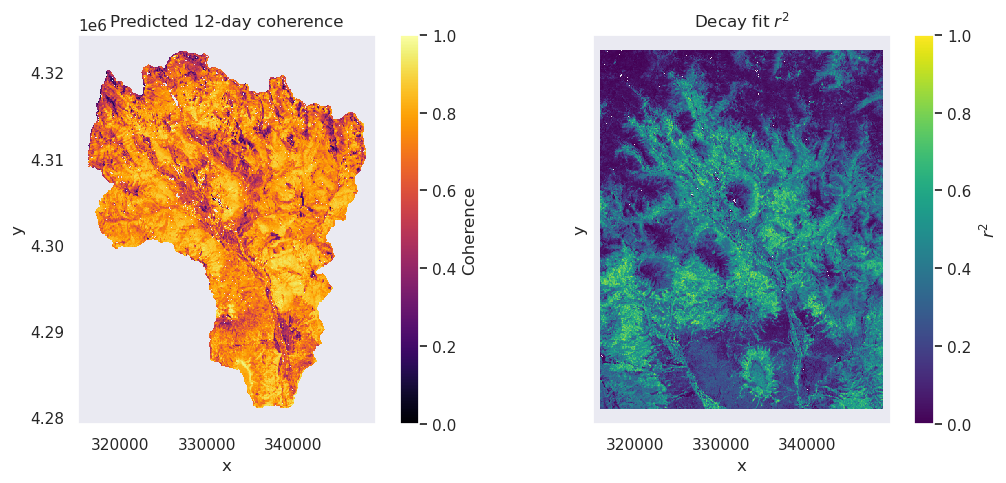

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
coh_pred.plot(ax=axes[0], cmap='inferno', vmin=0, vmax=1, cbar_kwargs={'label': 'Coherence'})
fit_grid['nse'].where(good).plot(ax=axes[1], cmap='viridis', vmin=0, vmax=1, cbar_kwargs={'label': 'NSE'})
axes[0].set_title(f'Predicted {target_days}-day coherence')
axes[1].set_title('Decay fit NSE')
for ax in axes:
    ax.set_aspect('equal')
    ax.grid(False)
plt.tight_layout()
plt.show()

Observed coherence and the difference from the prediction for every pair.

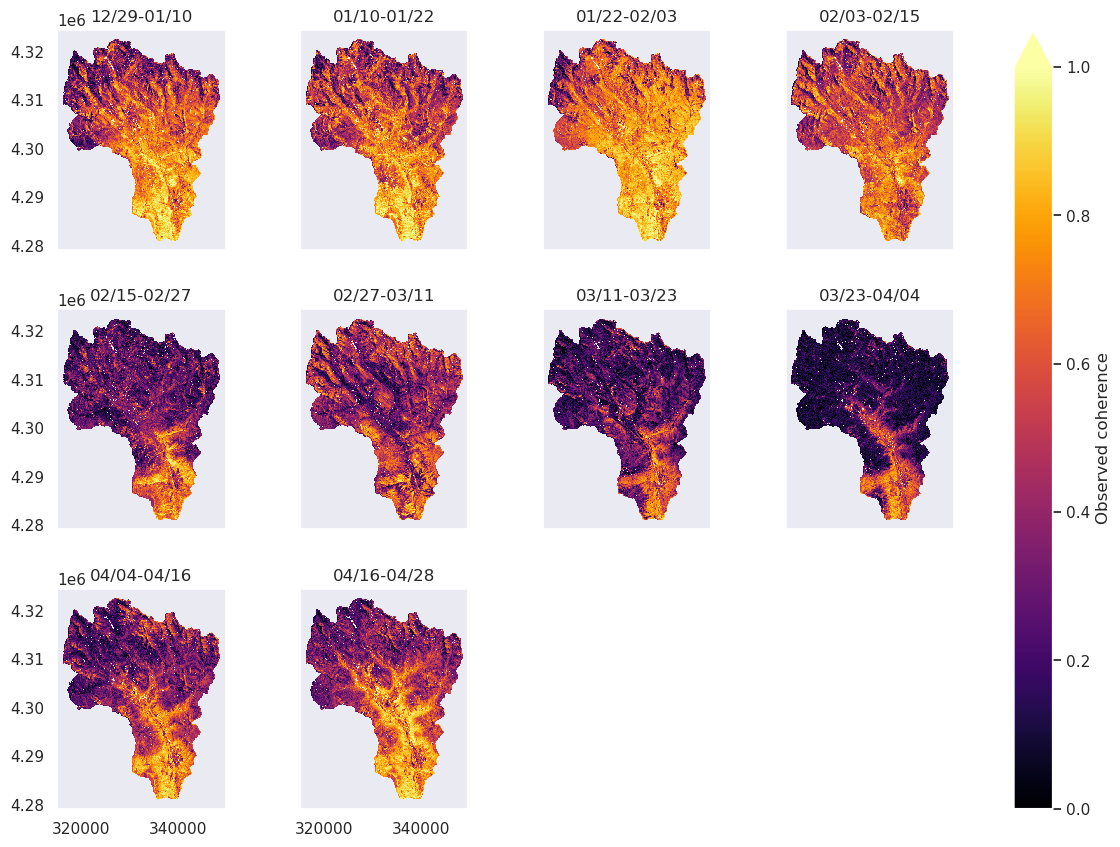

In [11]:
g = map_panels(coh_obs.where(valid), cmap='inferno', vmin=0, vmax=1, cbar_kwargs={'label': 'Observed coherence'})
plt.show()

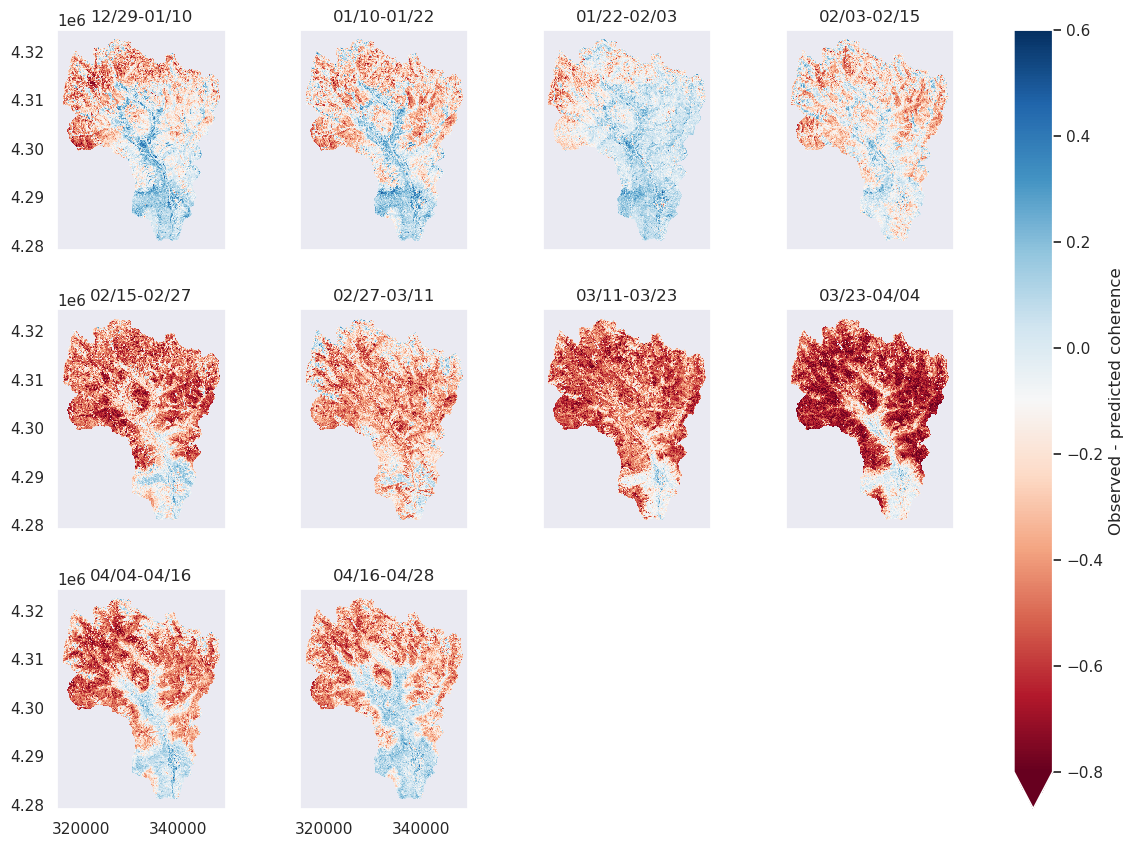

In [64]:
g = map_panels(coh_diff, cmap='RdBu', vmin=-0.8, vmax=0.6, cbar_kwargs={'label': 'Observed - predicted coherence'})
plt.show()

Optionally save the predicted coherence and the differences as a Zarr and as GeoTIFFs (set `save_outputs = True`).

In [13]:
out = xr.Dataset({'coh_obs': coh_obs, 'coh_pred': coh_pred, 'coh_diff': coh_diff})
out = out.assign_attrs(decay_path=decay_path, coh_path=coh_path, coh_var=coh_var, target_days=target_days,
                       start_date=start_date, end_date=end_date, min_nse=min_nse)
if save_outputs:
    os.makedirs(out_dir, exist_ok=True)
    out.to_zarr(out_dir + out_name + '.zarr', mode='w')
    tif_dir = Path(out_dir + out_name + '_tifs')
    tif_dir.mkdir(exist_ok=True)
    for k in ['coh_pred', 'coh_diff']:
        out[k].rio.write_crs(crs).rio.to_raster(tif_dir / f'{k}.tif')

In [14]:
coh

<xarray.Dataset> Size: 2GB
Dimensions:                     (pair: 300, y: 566, x: 433)
Coordinates:
  * pair                        (pair) <U17 20kB '20251123_20251205' ... '202...
    start                       (pair) datetime64[ns] 2kB dask.array<chunksize=(300,), meta=np.ndarray>
    end                         (pair) datetime64[ns] 2kB dask.array<chunksize=(300,), meta=np.ndarray>
  * y                           (y) float64 5kB 4.324e+06 ... 4.279e+06
  * x                           (x) float64 3kB 3.151e+05 ... 3.496e+05
Data variables:
    gamma_spatial               (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_temporal              (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_thermal               (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    canopy_2021                 (y, x) float32 980kB dask.array<chunksize=(283, 217), meta=np.ndarray>
    coherence_true              (pair, y, x) float64 588MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_temporal_uncorrected  (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    spatial_ref                 int64 8B ...
    coherence                   (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    elevation                   (y, x) float32 980kB dask.array<chunksize=(283, 217), meta=np.ndarray>
Attributes:
    crs:                   EPSG:32613
    track:                 19
    frame:                 21
    utc_offset_hours:      -7
    spatial_res:           3
    wavelength:            0.24
    incidence_to_radians:  1
    aso:                   None

In [46]:
coh

<xarray.Dataset> Size: 2GB
Dimensions:                     (pair: 300, y: 566, x: 433)
Coordinates:
  * pair                        (pair) <U17 20kB '20251123_20251205' ... '202...
    start                       (pair) datetime64[ns] 2kB dask.array<chunksize=(300,), meta=np.ndarray>
    end                         (pair) datetime64[ns] 2kB dask.array<chunksize=(300,), meta=np.ndarray>
  * y                           (y) float64 5kB 4.324e+06 ... 4.279e+06
  * x                           (x) float64 3kB 3.151e+05 ... 3.496e+05
Data variables:
    gamma_spatial               (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_temporal              (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_thermal               (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    canopy_2021                 (y, x) float32 980kB dask.array<chunksize=(283, 217), meta=np.ndarray>
    coherence_true              (pair, y, x) float64 588MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    gamma_temporal_uncorrected  (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    spatial_ref                 int64 8B ...
    coherence                   (pair, y, x) float32 294MB dask.array<chunksize=(5, 256, 256), meta=np.ndarray>
    elevation                   (y, x) float32 980kB dask.array<chunksize=(283, 217), meta=np.ndarray>
Attributes:
    crs:                   EPSG:32613
    track:                 19
    frame:                 21
    utc_offset_hours:      -7
    spatial_res:           3
    wavelength:            0.24
    incidence_to_radians:  1
    aso:                   None

In [50]:
# Scene-average coherence of every pair starting/ending inside [start_date, end_date] (any temporal baseline)
# vs temporal baseline. Line = median over pairs at each baseline, band = IQR, dashed = decay fit.

fit_stat = 'median'   # 'median' or 'mean': how the per-pixel decay fit is averaged over the scene


# 1. Pairs whose first (reference) date is inside the time window. The second date can be later,
#    so any temporal baseline is kept.
window_rule = 'both'   # 'start': start date in window | 'either': start or end in window | 'both': both in window

baseline_days = ((coh['end'] - coh['start']) / np.timedelta64(1, 'D')).values
t0, t1 = np.datetime64(start_date), np.datetime64(end_date) + np.timedelta64(1, 'D')
start_in = ((coh['start'] >= t0) & (coh['start'] < t1)).values
end_in = ((coh['end'] >= t0) & (coh['end'] < t1)).values
in_window = {'start': start_in, 'either': start_in | end_in, 'both': start_in & end_in}[window_rule]
idx = np.where(in_window)[0]
idx2 = np.where(coh['start'] >= t1)[0]
if len(idx) == 0:
    raise ValueError(f'No pairs between {start_date} and {end_date}')

# 2. Same pixels for the observations and the fit: canopy/elevation mask and a successful decay fit
mask = valid & good

# 3. Scene-average observed coherence for each pair in the window
scene_mean = coh[coh_var].isel(pair=idx).where(mask).mean(dim=['x', 'y']).compute()

pair_df = pd.DataFrame({
    'baseline': np.round(baseline_days[idx]).astype(int),  # whole days so equal baselines group together
    'coh': scene_mean.values,
    'wet': (coh['end'].values[idx] > np.datetime64(wet_after)),
}).dropna()
print(f'{len(pair_df)} of {coh.sizes["pair"]} pairs plotted ({pair_df["wet"].sum()} wet)')

# 4. Median and interquartile range from ALL pairs in the cube (not just the windowed ones)
all_mean = coh[coh_var].isel(pair=idx2).where(mask).mean(dim=['x', 'y']).compute()
all_df = pd.DataFrame({
    'baseline': np.round(baseline_days).astype(int)[idx2],
    'coh': all_mean.values,
}).dropna()
print(f'median/IQR from {len(all_df)} pairs, dots from {len(pair_df)} pairs')

by_base = all_df.groupby('baseline')['coh']
stats = pd.DataFrame({'median': by_base.median(),
                      'q25': by_base.quantile(0.25),
                      'q75': by_base.quantile(0.75)})

# 5. Decay fit evaluated per pixel at each baseline, then summarized over the scene
t_fit = np.arange(all_df['baseline'].min(), all_df['baseline'].max() + 1)
fit_curve = []
for t in t_fit:
    pred_t = decorrelation_temporal_model(float(t), fit_grid['gamma_0'], fit_grid['gamma_inf'], fit_grid['tau']).where(mask)
    fit_curve.append(float(pred_t.median() if fit_stat == 'median' else pred_t.mean()))



55 of 300 pairs plotted (40 wet)
median/IQR from 55 pairs, dots from 55 pairs


In [57]:
fit_grid['nse'].mean()

<xarray.DataArray 'r2' ()> Size: 4B
array(0.30511984, dtype=float32)

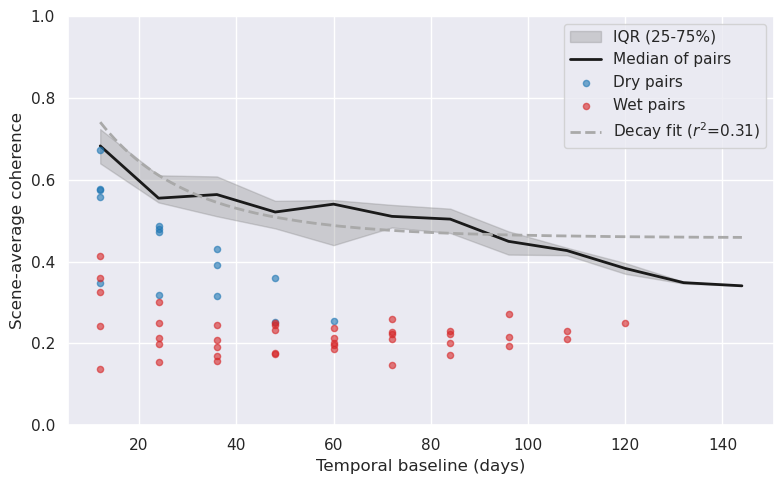

In [63]:
# 6. Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(stats.index, stats['q25'], stats['q75'], color='gray', alpha=0.3, label='IQR (25-75%)')
ax.plot(stats.index, stats['median'], c='k', lw=2, label=f'Median of pairs')
# ax.scatter(all_df['baseline'], all_df['coh'], marker='x',
#            c='darkgray', s=20, alpha=0.6, label='', zorder=0)
ax.scatter(pair_df['baseline'][~pair_df['wet']], pair_df['coh'][~pair_df['wet']],
           c='tab:blue', s=20, alpha=0.6, label='Dry pairs', zorder=3)
ax.scatter(pair_df['baseline'][pair_df['wet']], pair_df['coh'][pair_df['wet']],
           c='tab:red', s=20, alpha=0.6, label='Wet pairs', zorder=4)
ax.plot(t_fit, fit_curve, c='darkgray', ls='--', lw=2, label=f'Decay fit (NSE={fit_grid["nse"].mean().values:.2f})', zorder=5)
ax.set_xlabel('Temporal baseline (days)')
ax.set_ylabel('Scene-average coherence')
ax.set_ylim([0, 1])
ax.legend()
plt.tight_layout()
plt.show()

In [53]:
fsca = xr.open_zarr(fsca_path)['fsca']
fsca = fsca.rio.write_crs(crs) if fsca.rio.crs is None else fsca
fsca = match_grid(fsca, grid_ref, crs).load()

snow_class = classify_fsca(fsca)
coh_subset = coh.isel(pair=idx)
snow_change = classify_change(snow_class, coh_subset['start'], coh_subset['end'], pair=coh_subset['pair'], tolerance='1D')
change_labels = snow_change.attrs['change_labels']

2026-11-04 15:11:25,931 - INFO - Resampling fsca onto the reference grid


In [54]:
# 3. Scene-average observed coherence for each pair in the window
scene_mean = coh[coh_var].isel(pair=idx).where(snow_change > 0).where(mask).mean(dim=['x', 'y']).compute()

pair_df = pd.DataFrame({
    'baseline': np.round(baseline_days[idx]).astype(int),  # whole days so equal baselines group together
    'coh': scene_mean.values,
    'wet': (coh['end'].values[idx] > np.datetime64(wet_after)),
}).dropna()
print(f'{len(pair_df)} of {coh.sizes["pair"]} pairs plotted ({pair_df["wet"].sum()} wet)')

55 of 300 pairs plotted (40 wet)


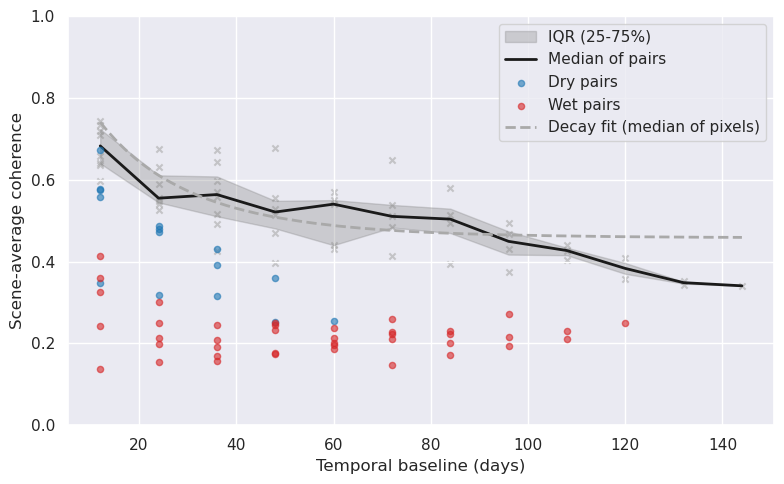

In [55]:
# 6. Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(stats.index, stats['q25'], stats['q75'], color='gray', alpha=0.3, label='IQR (25-75%)')
ax.plot(stats.index, stats['median'], c='k', lw=2, label='Median of pairs')
ax.scatter(all_df['baseline'], all_df['coh'], marker='x',
           c='darkgray', s=20, alpha=0.6, label='', zorder=0)
ax.scatter(pair_df['baseline'][~pair_df['wet']], pair_df['coh'][~pair_df['wet']],
           c='tab:blue', s=20, alpha=0.6, label='Dry pairs', zorder=3)
ax.scatter(pair_df['baseline'][pair_df['wet']], pair_df['coh'][pair_df['wet']],
           c='tab:red', s=20, alpha=0.6, label='Wet pairs', zorder=4)
ax.plot(t_fit, fit_curve, c='darkgray', ls='--', lw=2, label=f'Decay fit ({fit_stat} of pixels)', zorder=5)
ax.set_xlabel('Temporal baseline (days)')
ax.set_ylabel('Scene-average coherence')
ax.set_ylim([0, 1])
ax.legend()
plt.tight_layout()
plt.show()

# 2. Predicted coherence by aspect, elevation and vegetation

Flatten the maps into a table with one row per pixel. Pixels without a prediction, or without an aspect (flat), are dropped.

In [20]:
df = pd.DataFrame({
    'pred': coh_pred.values.ravel(),
    'elevation': elevation.values.ravel(),
    'canopy': canopy.values.ravel(),
    'aspect': aspect.values.ravel(),
}).dropna()
df = df[df['aspect'] >= 0]  # xrspatial marks flat cells with -1
len(df)

100342

Mean predicted coherence (with one standard deviation) in elevation bands, canopy cover bins and 8 aspect sectors.

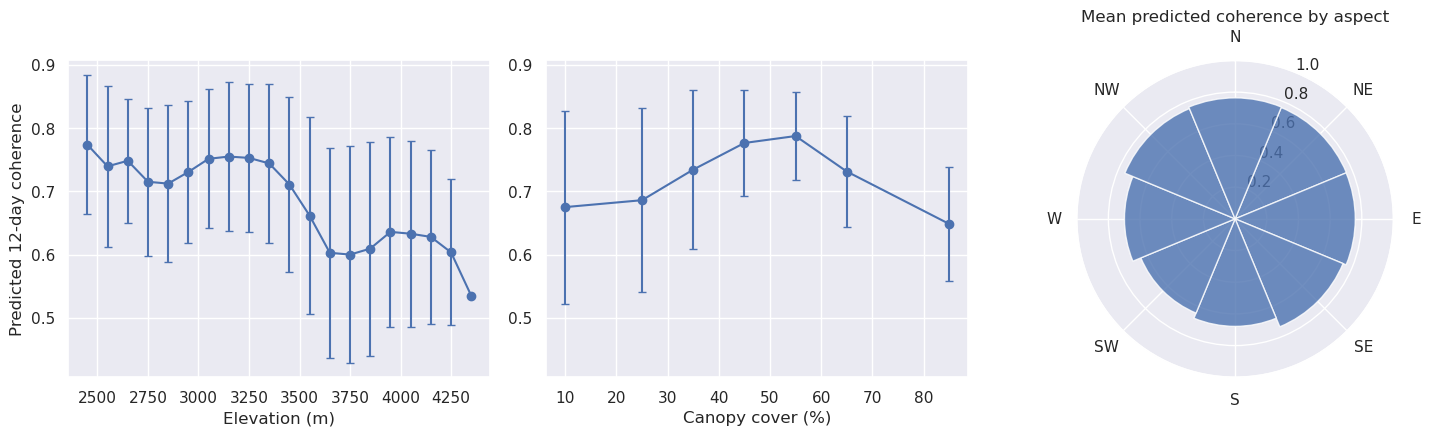

In [21]:
elev_bins = np.arange(np.floor(df['elevation'].min() / elev_step) * elev_step, df['elevation'].max() + elev_step, elev_step)

fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(1, 3, 1)
s = band_stats(df['elevation'], df['pred'], elev_bins)
ax.errorbar(s['mid'], s['mean'], yerr=s['std'], fmt='o-', capsize=3)
ax.set_xlabel('Elevation (m)')
ax.set_ylabel(f'Predicted {target_days}-day coherence')

ax = fig.add_subplot(1, 3, 2, sharey=ax)
s = band_stats(df['canopy'], df['pred'], canopy_bins)
ax.errorbar(s['mid'], s['mean'], yerr=s['std'], fmt='o-', capsize=3)
ax.set_xlabel('Canopy cover (%)')

ax = fig.add_subplot(1, 3, 3, projection='polar')
plot_rose(ax, aspect_stats(df['aspect'], df['pred']), 'Mean predicted coherence by aspect')
plt.tight_layout()
plt.show()

Elevation and canopy are correlated, so the next plot shows predicted coherence by elevation band for each canopy class.

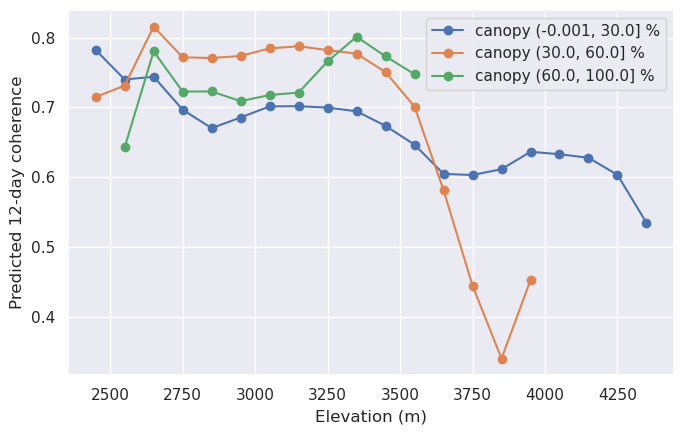

In [22]:
canopy_classes = pd.cut(df['canopy'], bins=[0, 30, 60, 100], include_lowest=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
for cls, sub in df.groupby(canopy_classes, observed=True):
    s = band_stats(sub['elevation'], sub['pred'], elev_bins)
    ax.plot(s['mid'], s['mean'], 'o-', label=f'canopy {cls} %')
ax.set_xlabel('Elevation (m)')
ax.set_ylabel(f'Predicted {target_days}-day coherence')
ax.legend()
plt.tight_layout()
plt.show()

# 3. A closer look at one pair

Choose a pair (`selected_pair` in the settings). By default this is the first wet pair, or the last pair if none is wet.

In [23]:
if selected_pair is None:
    selected_pair = pairs[wet][0] if wet.any() else pairs[-1]
print('selected pair:', selected_pair)

d_pair = coh_diff.sel(pair=selected_pair)
sel = pd.DataFrame({
    'pred': coh_pred.values.ravel(),
    'obs': coh_obs.sel(pair=selected_pair).values.ravel(),
    'diff': d_pair.values.ravel(),
    'elevation': elevation.values.ravel(),
    'aspect': aspect.values.ravel(),
}).dropna()
sel = sel[sel['aspect'] >= 0]

selected pair: 20260215_20260227


Maps of the difference and of aspect for this pair.

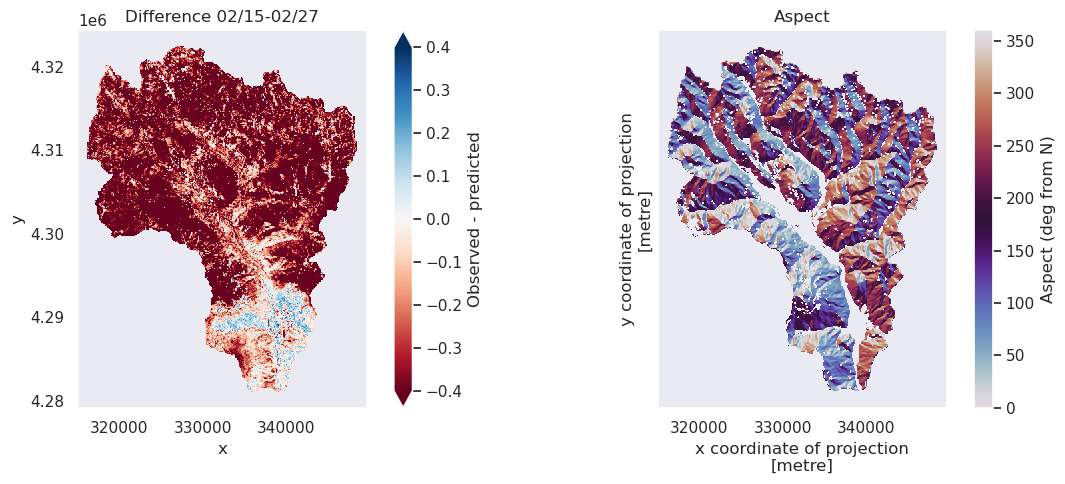

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
d_pair.plot(ax=axes[0], cmap='RdBu', vmin=-0.4, vmax=0.4, cbar_kwargs={'label': 'Observed - predicted'})
aspect.plot(ax=axes[1], cmap='twilight', vmin=0, vmax=360, cbar_kwargs={'label': 'Aspect (deg from N)'})
axes[0].set_title(f'Difference {pair_label(selected_pair)}')
axes[1].set_title('Aspect')
for ax in axes:
    ax.set_aspect('equal')
    ax.grid(False)
plt.tight_layout()
plt.show()

The difference against predicted coherence. The line is the mean difference in bins of predicted coherence.

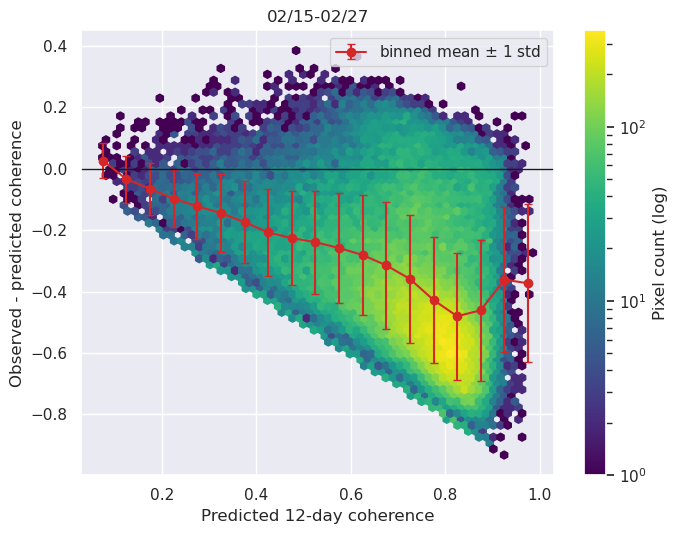

In [25]:
fig, ax = plt.subplots(figsize=(7, 5.5))
hb = ax.hexbin(sel['pred'], sel['diff'], gridsize=60, bins='log', cmap='viridis', mincnt=1)
s = band_stats(sel['pred'], sel['diff'], np.arange(0, 1.0001, 0.05))
ax.errorbar(s['mid'], s['mean'], yerr=s['std'], c='tab:red', fmt='o-', capsize=3, label='binned mean $\\pm$ 1 std')
ax.axhline(0, c='k', lw=1)
fig.colorbar(hb, label='Pixel count (log)')
ax.set_xlabel(f'Predicted {target_days}-day coherence')
ax.set_ylabel('Observed - predicted coherence')
ax.set_title(pair_label(selected_pair))
ax.legend()
plt.tight_layout()
plt.show()

The difference against aspect, as all pixels (colored by elevation) and as the mean in 15 degree sectors.

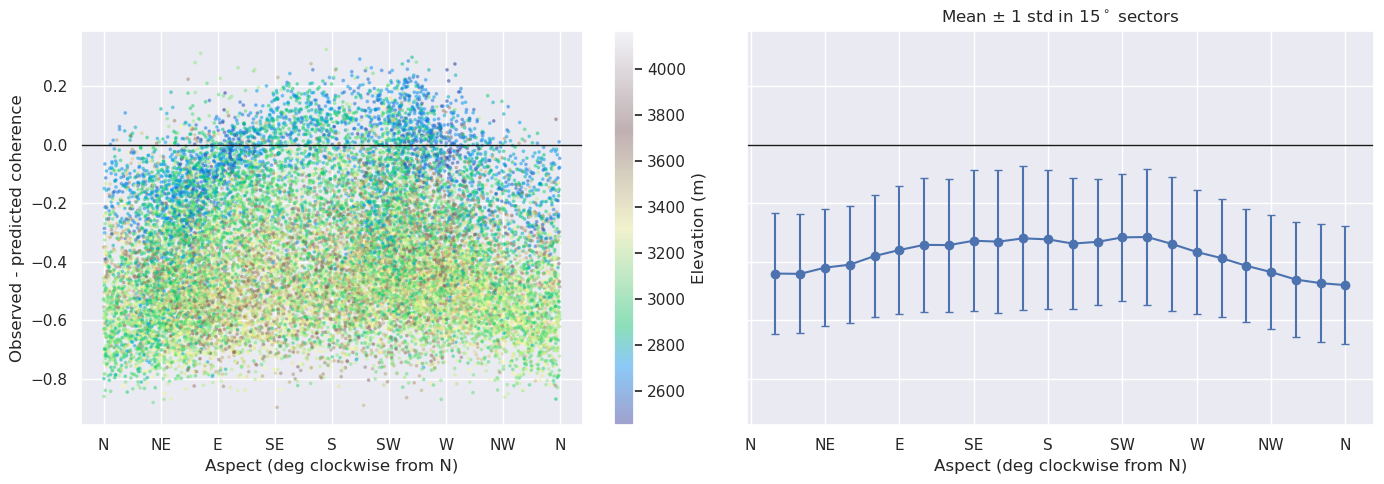

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sub = sel.sample(min(len(sel), 20000), random_state=0)
sc = axes[0].scatter(sub['aspect'], sub['diff'], c=sub['elevation'], s=3, alpha=0.4, cmap='terrain')
fig.colorbar(sc, ax=axes[0], label='Elevation (m)')
axes[0].set_ylabel('Observed - predicted coherence')

s = aspect_stats(sel['aspect'], sel['diff'], width=15)
axes[1].errorbar(s['mid'], s['mean'], yerr=s['std'], fmt='o-', capsize=3)
for ax in axes:
    ax.axhline(0, c='k', lw=1)
    ax.set_xlabel('Aspect (deg clockwise from N)')
    ax.set_xticks(np.arange(0, 361, 45))
    ax.set_xticklabels(sector_names + ['N'])
axes[1].set_title('Mean $\\pm$ 1 std in 15$^\\circ$ sectors')
plt.tight_layout()
plt.show()

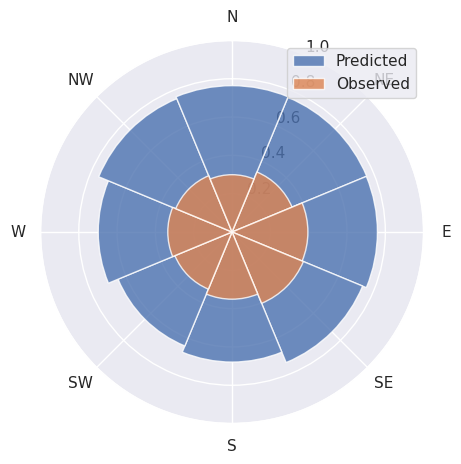

In [27]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
plot_rose(ax, aspect_stats(sel['aspect'], sel['pred']), '', label='Predicted')
plot_rose(ax, aspect_stats(sel['aspect'], sel['obs']), '', label='Observed')
ax.legend()
plt.tight_layout()
plt.show()

# 4. Deviation from the decay fit vs snow metrics

Summarize each pair by the mean and spread of its difference over all valid pixels.

In [28]:
summary = pd.DataFrame({
    'mean_diff': coh_diff.mean(dim=['x', 'y']).values,
    'median_diff': coh_diff.median(dim=['x', 'y']).values,
    'std_diff': coh_diff.std(dim=['x', 'y']).values,
    'mean_obs': coh_obs.where(coh_pred.notnull()).mean(dim=['x', 'y']).values,
    'wet': wet,
}, index=pairs)
summary

,mean_diff,median_diff,std_diff,mean_obs,wet
20251229_20260110,-0.125607,-0.112694,0.218635,0.583245,False
20260110_20260122,-0.132001,-0.134368,0.211905,0.576850,False
20260122_20260203,-0.025794,-0.002509,0.155096,0.683057,False
20260203_20260215,-0.148913,-0.140849,0.173593,0.559938,False
20260215_20260227,-0.358524,-0.387440,0.224965,0.350327,False
20260227_20260311,-0.284291,-0.298839,0.189378,0.424561,False
20260311_20260323,-0.418701,-0.450405,0.195274,0.290150,True
20260323_20260404,-0.489422,-0.551457,0.235029,0.219429,True
20260404_20260416,-0.289289,-0.316759,0.233126,0.419562,True
20260416_20260428,-0.209292,-0.225258,0.225445,0.499560,True


Load the SNOTEL snow water equivalent and the MesoWest wind, with the same time zone as the cubes.

In [29]:
wind_files = sorted(Path(data_dir + 'stations/mesowest/').glob('*.csv'))
wind_names = {
    'SOSC2': 'schofield_pass',
    'CACNM': 'cinnamon_mtn',
    'CASCP': 'irwins_ridge',
}

wind = read_mesowest(wind_files, wind_names, utc_offset_hours=-7)

snotel_files = sorted(Path(data_dir + 'stations/snotel/').glob('*WATERYEAR*.csv'))
snotel_names = {
    '1141': 'upper_taylor',
    '380':  'butte',
    '1326': 'castle_peak',
    '737':  'schofield_pass',
}
swe = read_snotel(snotel_files, snotel_names, utc_offset_hours=-7)

/bsuhome/julialober/nisar_snow_coherence/scripts/stations.py:49: DtypeWarning: Columns (0: pressure_set_1, 1: air_temp_set_1, 2: relative_humidity_set_1, 3: wind_speed_set_1, 4: wind_direction_set_1, 5: wind_gust_set_1, 6: snow_depth_set_1, 7: solar_radiation_set_1, 8: soil_temp_set_1, 9: precip_accum_set_1, 10: snow_interval_set_1, 11: T_water_temp_set_1, 12: evapotranspiration_set_1) have mixed types. Specify dtype option on import or set low_memory=False.
  ds = pd.read_csv(f, comment='#')
/bsuhome/julialober/nisar_snow_coherence/scripts/stations.py:49: DtypeWarning: Columns (0: air_temp_set_1, 1: relative_humidity_set_1, 2: wind_speed_set_1, 3: wind_speed_set_2, 4: wind_direction_set_1, 5: wind_direction_set_2, 6: wind_gust_set_1, 7: solar_radiation_set_1) have mixed types. Specify dtype option on import or set low_memory=False.
  ds = pd.read_csv(f, comment='#')


Mean difference for each pair (at the pair midpoint, bars are one standard deviation over pixels) with the SNOTEL SWE in the background. Orange lines are acquisition dates.

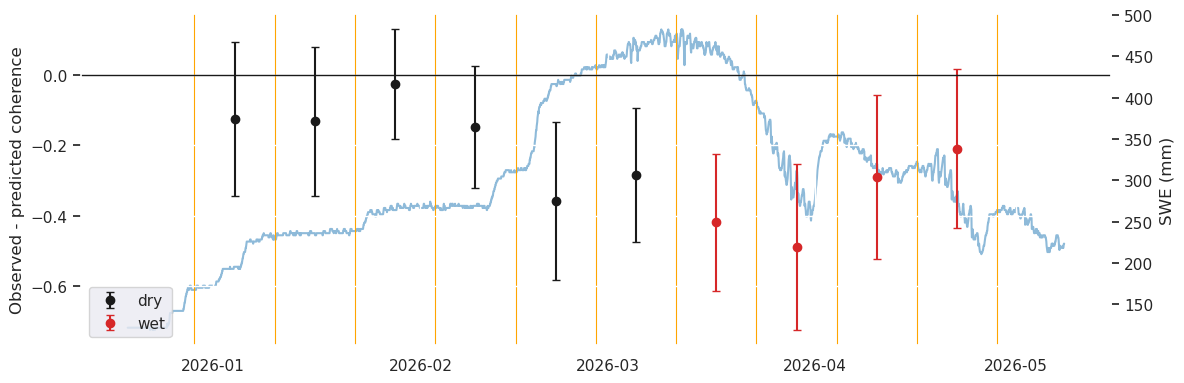

In [30]:
mid = starts + (ends - starts) / 2
swe_plot = swe['swe'].sel(station_name=swe_stns).mean(dim='station_id').sel(datetime=slice(starts.min() - np.timedelta64(10, 'D'), ends.max() + np.timedelta64(10, 'D')))

fig, ax = plt.subplots(figsize=(12, 4))
ax2 = ax.twinx()
ax2.plot(swe_plot.datetime, swe_plot, c='tab:blue', alpha=0.5)
ax2.set_ylabel('SWE (mm)')
ax2.grid(False)
ax.errorbar(mid[~wet], summary['mean_diff'][~wet], yerr=summary['std_diff'][~wet], fmt='o', c='k', capsize=3, label='dry')
ax.errorbar(mid[wet], summary['mean_diff'][wet], yerr=summary['std_diff'][wet], fmt='o', c='tab:red', capsize=3, label='wet')
for d in np.unique(np.concatenate([starts, ends])):
    ax.axvline(d, c='orange', lw=0.8, zorder=0)
ax.axhline(0, c='k', lw=1)
ax.set_ylabel('Observed - predicted coherence')
ax.legend(loc='lower left')
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
plt.tight_layout()
plt.show()

Compute the snow accumulation and wind metrics for each pair, as in the time series notebook.

In [31]:
metrics = pair_metrics(swe.sel(station_name=swe_stns)['swe_accum'],
                       wind['wind_speed'].sel(station_id=wind_stns),
                       wind['air_temp'].sel(station_name=swe_stns),
                       starts, ends,
                       event_threshold, event_freq=event_freq)
metrics = metrics.sel(pair=pairs)
metrics

<xarray.Dataset> Size: 2kB
Dimensions:                   (pair: 10)
Coordinates:
  * pair                      (pair) <U17 680B '20251229_20260110' ... '20260...
Data variables: (12/15)
    swe_tot                   (pair) float64 80B 60.96 10.16 ... -30.48 -58.42
    swe_loss                  (pair) float64 80B -40.64 -63.5 ... -185.4 -345.4
    swe_max_6h                (pair) float64 80B 7.62 5.08 7.62 ... 10.16 20.32
    swe_max_12h               (pair) float64 80B 15.24 2.54 12.7 ... 10.16 27.94
    swe_max_1d                (pair) float64 80B 27.94 5.08 ... 15.24 40.64
    wind_mean                 (pair) float64 80B 6.514 6.8 6.685 ... 5.757 6.72
    ...                        ...
    wind_event_6h             (pair) float64 80B 7.904 0.0 6.102 ... 4.842 5.647
    swe_max_6h_x_wind_event   (pair) float64 80B 60.23 0.0 46.5 ... 49.19 114.7
    wind_event_12h            (pair) float64 80B 7.161 0.0 6.149 ... 6.388 5.525
    swe_max_12h_x_wind_event  (pair) float64 80B 109.1 0.0 78.09 ... 64.9 154.4
    wind_event_1d             (pair) float64 80B 6.969 0.0 6.018 ... 6.305 6.137
    swe_max_1d_x_wind_event   (pair) float64 80B 194.7 0.0 107.0 ... 96.08 249.4

Each panel compares one station metric with the mean difference. There are only a few 12-day pairs, so treat the correlations as a guide.

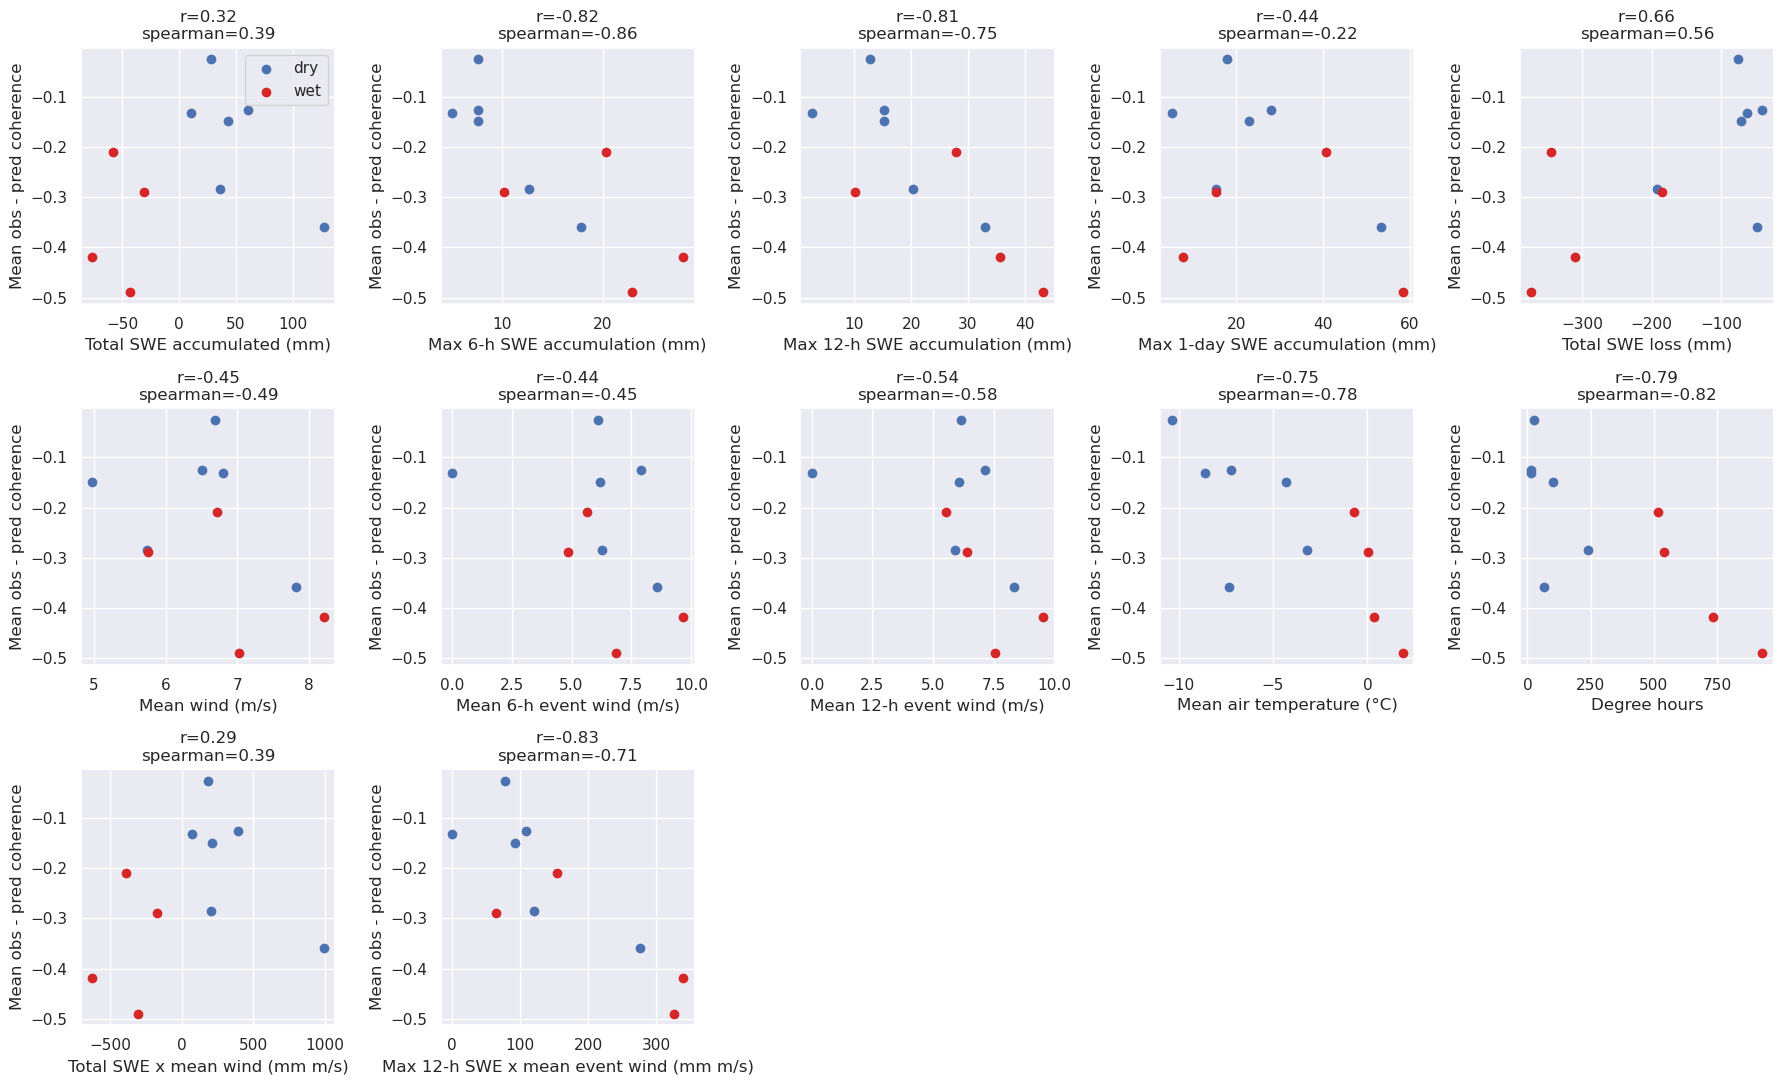

In [32]:
xlabels = {
    'swe_tot': 'Total SWE accumulated (mm)',
    'swe_max_6h': 'Max 6-h SWE accumulation (mm)',
    'swe_max_12h': 'Max 12-h SWE accumulation (mm)',
    'swe_max_1d': 'Max 1-day SWE accumulation (mm)',
    'swe_loss': 'Total SWE loss (mm)',
    'wind_mean': 'Mean wind (m/s)',
    'wind_event_6h': 'Mean 6-h event wind (m/s)',
    'wind_event_12h': 'Mean 12-h event wind (m/s)',
    'temp_mean': 'Mean air temperature (°C)',
    'degree_days': 'Degree hours',
    'swe_x_wind': 'Total SWE x mean wind (mm m/s)',
    'swe_max_12h_x_wind_event': 'Max 12-h SWE x mean event wind (mm m/s)',
}
yv = summary['mean_diff'].values


def corr_title(x, y):
    """Pearson and Spearman correlation of two arrays, ignoring NaNs."""
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3:
        return 'too few pairs'
    spear = pd.Series(x[ok]).rank().corr(pd.Series(y[ok]).rank(), method='spearman')
    return 'r={:.2f}\nspearman={:.2f}'.format(np.corrcoef(x[ok], y[ok])[0, 1], spear)


fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for ax, (k, xlabel) in zip(axes.flatten(), xlabels.items()):
    x = metrics[k].values
    ax.scatter(x[~wet], yv[~wet], label='dry')
    ax.scatter(x[wet], yv[wet], c='tab:red', label='wet')
    ax.set_title(corr_title(x, yv))
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Mean obs - pred coherence')
for ax in axes.flatten()[len(xlabels):]:
    ax.axis('off')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

One metric in detail, with each point labeled by its date range (`focus_metric` in the settings).

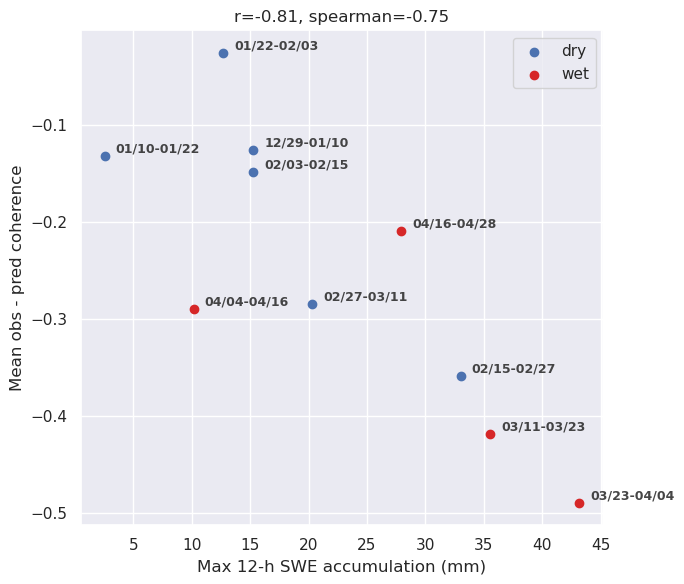

In [33]:
x = metrics[focus_metric].values
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x[~wet], yv[~wet], label='dry')
ax.scatter(x[wet], yv[wet], c='tab:red', label='wet')
for p, xi, yi in zip(pairs, x, yv):
    ax.annotate(pair_label(p), (xi, yi), textcoords='offset points', xytext=(8, 5), ha='left', va='center',
                fontsize=9, fontweight='semibold', alpha=0.85, zorder=5)
ax.set_title(corr_title(x, yv).replace('\n', ', '))
ax.set_xlabel(xlabels[focus_metric])
ax.set_ylabel('Mean obs - pred coherence')
ax.legend()
plt.tight_layout()
plt.show()

Where in the elevation range does each pair deviate most? Each cell is the mean difference in one elevation band.

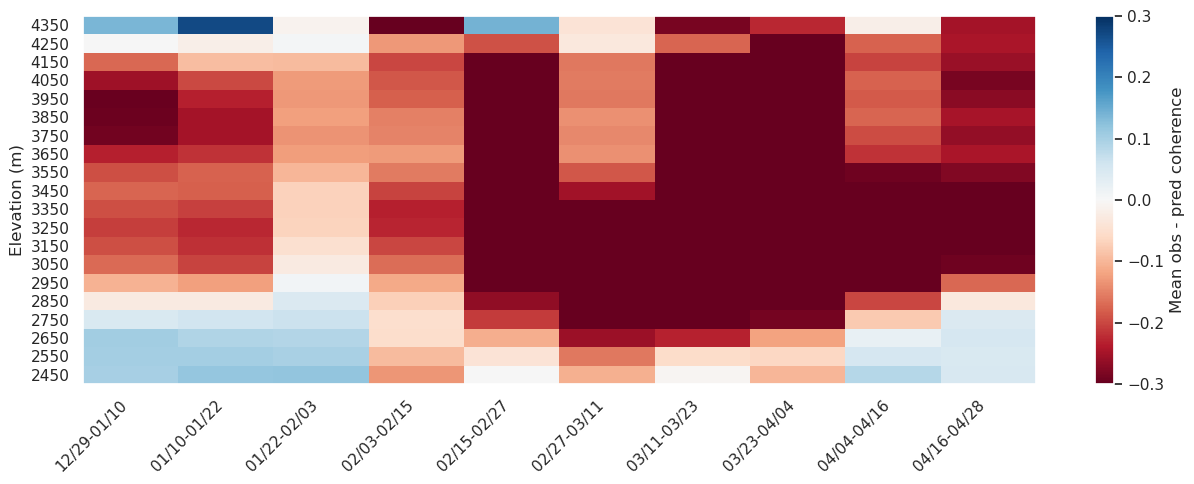

In [34]:
elev_flat = elevation.values.ravel()
elev_cut = pd.cut(elev_flat, bins=elev_bins, include_lowest=True)
heat = pd.DataFrame({p: pd.Series(coh_diff.sel(pair=p).values.ravel()).groupby(elev_cut, observed=True).mean()
                     for p in pairs})
heat.index = [iv.mid for iv in heat.index]

fig, ax = plt.subplots(figsize=(1.0 * len(pairs) + 3, 5))
im = ax.imshow(heat.values, aspect='auto', origin='lower', cmap='RdBu', vmin=-0.3, vmax=0.3)
ax.set_xticks(range(len(pairs)))
ax.set_xticklabels([pair_label(p) for p in pairs], rotation=45, ha='right')
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([f'{v:.0f}' for v in heat.index])
ax.set_ylabel('Elevation (m)')
ax.grid(False)
fig.colorbar(im, label='Mean obs - pred coherence')
plt.tight_layout()
plt.show()

Distribution of the pixel differences for each pair.

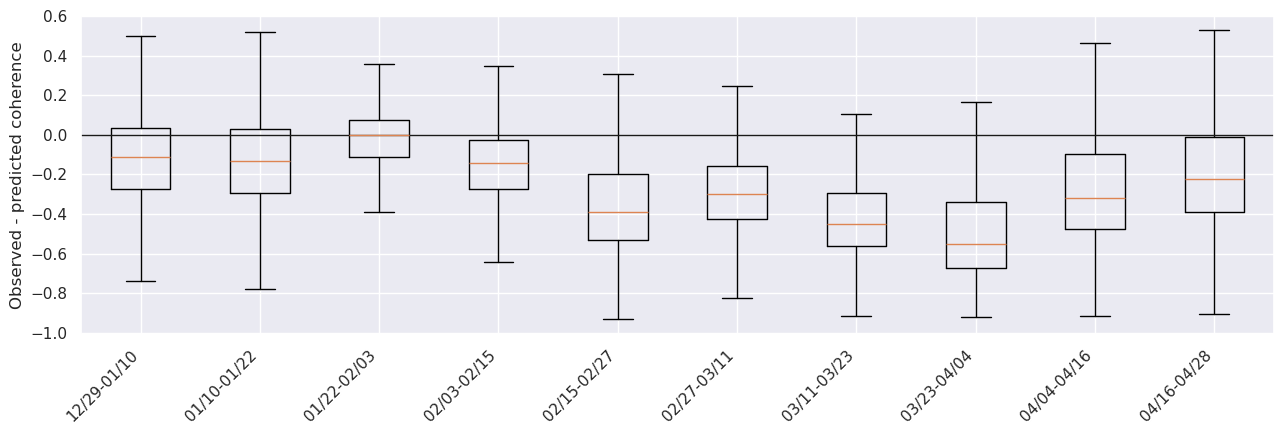

In [35]:
fig, ax = plt.subplots(figsize=(1.0 * len(pairs) + 3, 4.5))
vals = [coh_diff.sel(pair=p).values.ravel() for p in pairs]
ax.boxplot([v[np.isfinite(v)] for v in vals], showfliers=False)
ax.set_xticklabels([pair_label(p) for p in pairs], rotation=45, ha='right')
ax.axhline(0, c='k', lw=1)
ax.set_ylabel('Observed - predicted coherence')
plt.tight_layout()
plt.show()

## Snow-covered area (SPIRES fSCA)

Classify fSCA into no snow, patchy and snow, and find the change in class between the start and end of each pair.

In [36]:
fsca = xr.open_zarr(fsca_path)['fsca']
fsca = fsca.rio.write_crs(crs) if fsca.rio.crs is None else fsca
fsca = match_grid(fsca, grid_ref, crs).load()

snow_class = classify_fsca(fsca)
snow_change = classify_change(snow_class, starts, ends, pair=pairs, tolerance='1D')
change_labels = snow_change.attrs['change_labels']

2026-11-04 15:02:24,703 - INFO - Resampling fsca onto the reference grid


Pixel differences for each snow-cover change class, pooled over all pairs. Classes with fewer than 100 pixels are skipped.

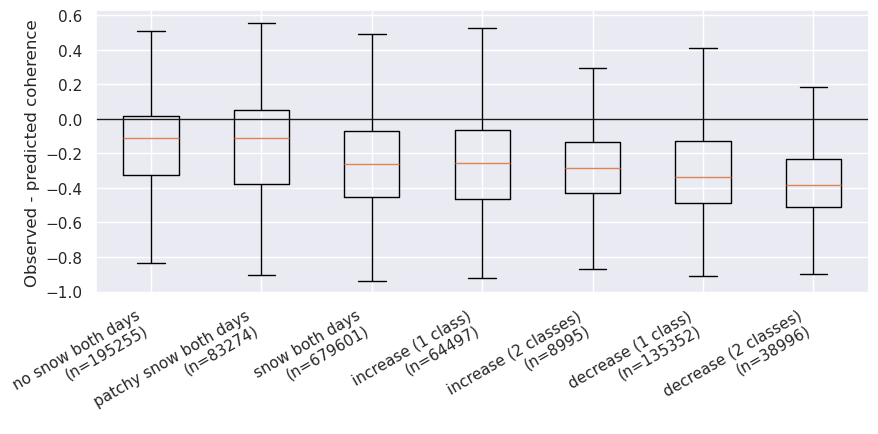

In [37]:
codes = snow_change.values.ravel()
dvals = coh_diff.values.ravel()
ok = np.isfinite(dvals) & (codes >= 0)
groups = {c: dvals[ok & (codes == c)] for c in np.unique(codes[ok])}
groups = {c: v for c, v in groups.items() if len(v) >= 100}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(list(groups.values()), showfliers=False)
ax.set_xticklabels([f'{change_labels[int(c)]}\n(n={len(v)})' for c, v in groups.items()], rotation=30, ha='right')
ax.axhline(0, c='k', lw=1)
ax.set_ylabel('Observed - predicted coherence')
plt.tight_layout()
plt.show()

Domain mean fSCA of each pair (average of its two dates) against the mean difference.

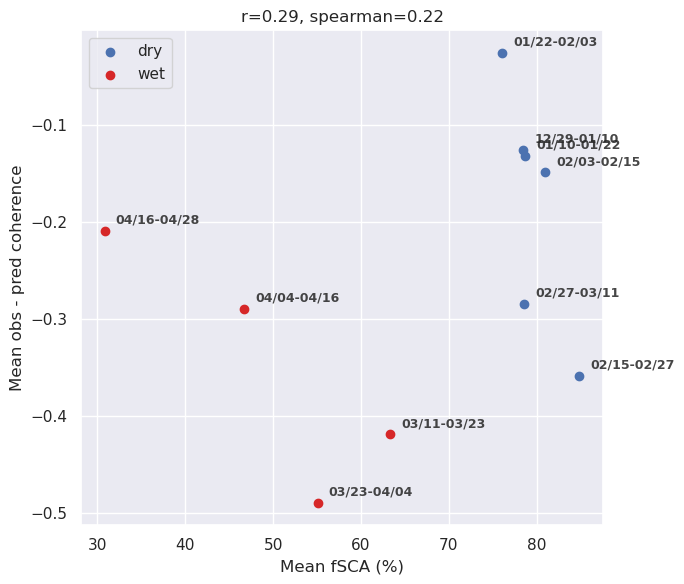

In [38]:
def fsca_on(dates):
    """fSCA on the nearest date, one layer per pair."""
    out = fsca.sel(time=xr.DataArray(pd.DatetimeIndex(dates).normalize(), dims='pair'), method='nearest', tolerance='1D')
    return out.drop_vars('time').assign_coords(pair=pairs)


fsca_pair = (fsca_on(starts) + fsca_on(ends)) / 2
summary['fsca_mean'] = fsca_pair.where(coh_diff.notnull()).mean(dim=['x', 'y']).values

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(summary['fsca_mean'][~wet], yv[~wet], label='dry')
ax.scatter(summary['fsca_mean'][wet], yv[wet], c='tab:red', label='wet')
for p, xi, yi in zip(pairs, summary['fsca_mean'], yv):
    ax.annotate(pair_label(p), (xi, yi), textcoords='offset points', xytext=(8, 5), fontsize=9, fontweight='semibold', alpha=0.85)
ax.set_title(corr_title(summary['fsca_mean'].values, yv).replace('\n', ', '))
ax.set_xlabel('Mean fSCA (%)')
ax.set_ylabel('Mean obs - pred coherence')
ax.legend()
plt.tight_layout()
plt.show()

## ASO snow depth

ASO is a single survey, so it can only be compared with one pair, here the selected pair. The 3 m depth is averaged onto the cube grid, and the date gap between the pair and the survey is printed.

ASO survey is 19 days after the end of 20260215_20260227


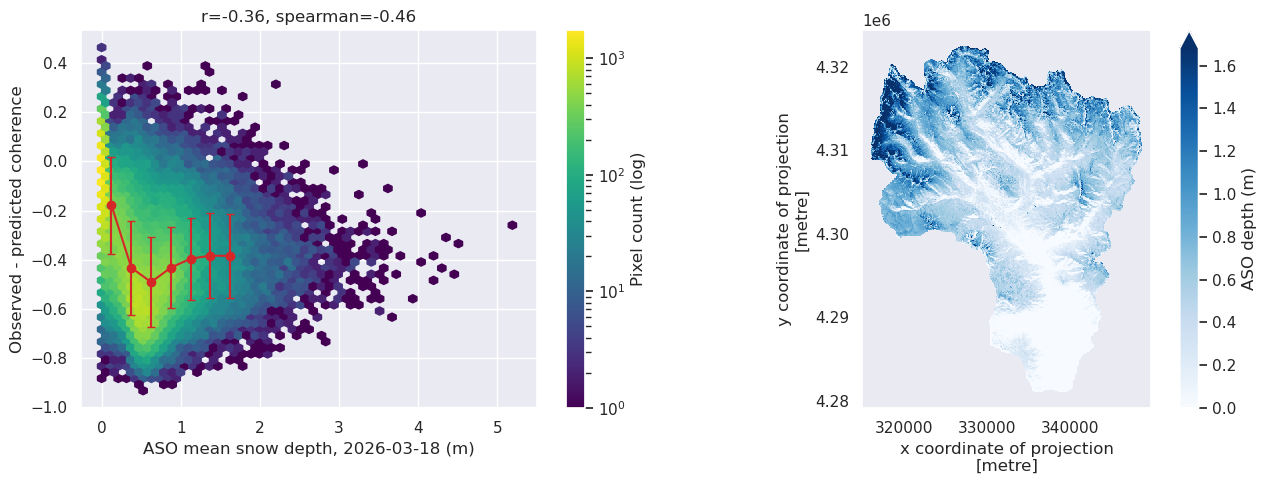

In [39]:
aso_3m = rioxarray.open_rasterio(aso_path, masked=True, chunks={'x': 2048, 'y': 2048}).squeeze(drop=True)
aso_mean = aso_3m.rio.reproject_match(coh_pred.rio.write_crs(crs), resampling=Resampling.average).load()
aso_mean = aso_mean.drop_vars('spatial_ref', errors='ignore')
gap_days = (np.datetime64(aso_date) - np.datetime64(pd.Timestamp(ends[list(pairs).index(selected_pair)]))) / np.timedelta64(1, 'D')
print(f'ASO survey is {gap_days:.0f} days after the end of {selected_pair}')

aso_df = pd.DataFrame({'depth': aso_mean.values.ravel(), 'diff': d_pair.values.ravel(),
                       'elevation': elevation.values.ravel()}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(aso_df['depth'], aso_df['diff'], gridsize=50, bins='log', cmap='viridis', mincnt=1)
s = band_stats(aso_df['depth'], aso_df['diff'], np.arange(0, aso_df['depth'].quantile(0.99), 0.25))
axes[0].errorbar(s['mid'], s['mean'], yerr=s['std'], c='tab:red', fmt='o-', capsize=3)
axes[0].set_xlabel(f'ASO mean snow depth, {aso_date} (m)')
axes[0].set_ylabel('Observed - predicted coherence')
axes[0].set_title(corr_title(aso_df['depth'].values, aso_df['diff'].values).replace('\n', ', '))
fig.colorbar(hb, ax=axes[0], label='Pixel count (log)')

aso_mean.plot(ax=axes[1], cmap='Blues', robust=True, cbar_kwargs={'label': 'ASO depth (m)'})
axes[1].set_aspect('equal')
axes[1].grid(False)
plt.tight_layout()
plt.show()

The table of per-pair metrics and the mean difference, for reference or saving.

In [40]:
table = summary.join(metrics.to_dataframe())
table

,mean_diff,median_diff,std_diff,mean_obs,wet,fsca_mean,swe_tot,swe_loss,swe_max_6h,swe_max_12h,...,wind_mean,temp_mean,degree_days,swe_x_wind,wind_event_6h,swe_max_6h_x_wind_event,wind_event_12h,swe_max_12h_x_wind_event,wind_event_1d,swe_max_1d_x_wind_event
20251229_20260110,-0.125607,-0.112694,0.218635,0.583245,False,78.485794,60.96,-40.64,7.62,15.24,...,6.514023,-7.200509,15.33,397.094869,7.903663,60.225914,7.161271,109.137767,6.969308,194.722467
20260110_20260122,-0.132001,-0.134368,0.211905,0.576850,False,78.675095,10.16,-63.50,5.08,2.54,...,6.800486,-8.617361,15.10,69.092939,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
20260122_20260203,-0.025794,-0.002509,0.155096,0.683057,False,76.048309,27.94,-76.20,7.62,12.70,...,6.684948,-10.369468,26.50,186.777445,6.101708,46.495017,6.148646,78.087802,6.018281,107.005041
20260203_20260215,-0.148913,-0.140849,0.173593,0.559938,False,80.923073,43.18,-71.12,7.62,15.24,...,4.980716,-4.306528,101.00,215.067299,6.197351,47.223816,6.069869,92.504808,4.642609,106.130035
20260215_20260227,-0.358524,-0.387440,0.224965,0.350327,False,84.861038,127.00,-48.26,17.78,33.02,...,7.819556,-7.317088,66.50,993.083632,8.561581,152.224902,8.342345,275.464243,7.974783,425.374904
20260227_20260311,-0.284291,-0.298839,0.189378,0.424561,False,78.534065,35.56,-193.04,12.70,20.32,...,5.736715,-3.218403,238.87,203.997578,6.281806,79.778931,5.919050,120.275090,5.609868,85.494389
20260311_20260323,-0.418701,-0.450405,0.195274,0.290150,True,63.320999,-76.20,-309.88,27.94,35.56,...,8.200833,0.326996,732.69,-624.903500,9.681621,270.504501,9.544219,339.392419,0.000000,0.000000
20260323_20260404,-0.489422,-0.551457,0.235029,0.219429,True,55.055004,-43.18,-373.38,22.86,43.18,...,7.020807,1.868942,928.92,-303.158459,6.881296,157.306420,7.555388,326.241665,8.138138,475.430023
20260404_20260416,-0.289289,-0.316759,0.233126,0.419562,True,46.711994,-30.48,-185.42,10.16,10.16,...,5.757027,0.021563,540.92,-175.474180,4.841949,49.194206,6.388125,64.903350,6.304505,96.080659
20260416_20260428,-0.209292,-0.225258,0.225445,0.499560,True,30.811022,-58.42,-345.44,20.32,27.94,...,6.719922,-0.720556,516.70,-392.577836,5.646515,114.737188,5.524839,154.364002,6.136594,249.391170
